# Lab 1.3 - Generate Handwritten Digits with a VAE (Solution)
**Day 1 - Session 3**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kpassoubady/gen-ai-companion-intuite/blob/main/day1/lab1_3_vae/solution/lab1_3_vae.ipynb)

**Goal:** Build and train a small variational autoencoder (VAE) on MNIST, then
sample its latent space to generate brand-new handwritten digits.

The dataset and epochs are capped so every cell finishes in a few minutes on a
Colab CPU runtime. No GPU needed.

In [1]:
# Scoped install for this lab (safe to re-run; preinstalled on Colab).
%pip install -q torch torchvision matplotlib

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 1. Load a slice of MNIST
We use 12,000 training images so training stays quick on CPU. Each image is a
28x28 grayscale handwritten digit.

In [3]:
transform = transforms.ToTensor()
train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_ds = Subset(train_full, range(12000))
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
print("Training images:", len(train_ds))

100%|██████████| 9.91M/9.91M [00:00<00:00, 46.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.13MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.20MB/s]

Training images: 12000


## 2. Define the VAE
The encoder maps an image to a mean and log-variance. The reparameterization
trick samples a latent vector `z` so gradients can still flow. The decoder
turns `z` back into a 28x28 image.

In [4]:
LATENT_DIM = 16


class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(28 * 28, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 28 * 28), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.enc(x.view(-1, 28 * 28))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


model = VAE().to(device)
print(model)

VAE(
  (enc): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=16, bias=True)
  (dec): Sequential(
    (0): Linear(in_features=16, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


## 3. The VAE loss
Two terms: reconstruction loss (the output should match the input) plus KL
divergence (keep the latent space close to a standard normal so we can sample
from it).

In [5]:
def vae_loss(recon, x, mu, logvar):
    recon_loss = F.binary_cross_entropy(recon, x.view(-1, 28 * 28), reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl

## 4. Train
Five epochs is enough to generate recognizable digits.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    model.train()
    running = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = model(images)
        loss = vae_loss(recon, images, mu, logvar)
        loss.backward()
        optimizer.step()
        running += loss.item()
    print(f"epoch {epoch + 1}: avg loss {running / len(train_ds):.2f}")

epoch 1: avg loss 250.10
epoch 2: avg loss 177.38
epoch 3: avg loss 155.10
epoch 4: avg loss 143.21
epoch 5: avg loss 136.21


## 5. Generate new digits
Sample random latent vectors from a standard normal and decode them. These
digits were never in the training data.

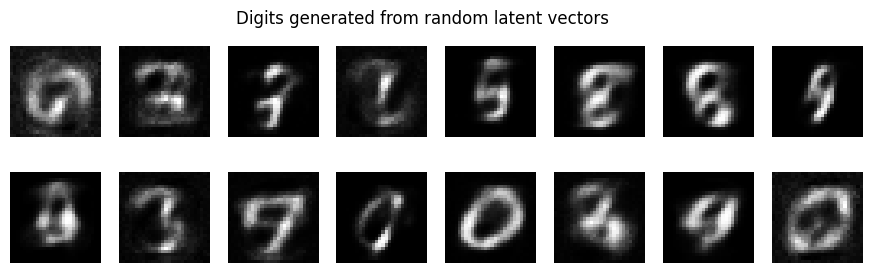

In [7]:
model.eval()
with torch.no_grad():
    z = torch.randn(16, LATENT_DIM, device=device)
    samples = model.decode(z).view(-1, 28, 28).cpu()

fig, axes = plt.subplots(2, 8, figsize=(11, 3))
for ax, img in zip(axes.flatten(), samples):
    ax.imshow(img, cmap="gray")
    ax.axis("off")
fig.suptitle("Digits generated from random latent vectors")
plt.show()

## Stretch goals
1. Interpolate between two latent vectors and decode each step to watch one
   digit morph into another.
2. Retrain with `LATENT_DIM = 2` and scatter the encoded training digits,
   coloring by their true label, to visualize the latent space.

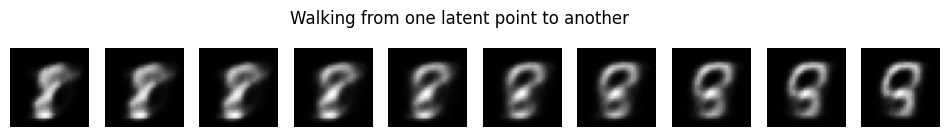

In [8]:
# Stretch 1: interpolate between two random latent points.
with torch.no_grad():
    z_a, z_b = torch.randn(1, LATENT_DIM, device=device), torch.randn(1, LATENT_DIM, device=device)
    steps = torch.linspace(0, 1, 10, device=device).view(-1, 1)
    z_walk = z_a * (1 - steps) + z_b * steps
    walk = model.decode(z_walk).view(-1, 28, 28).cpu()

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, img in zip(axes, walk):
    ax.imshow(img, cmap="gray")
    ax.axis("off")
fig.suptitle("Walking from one latent point to another")
plt.show()

### Expected output
- The average loss drops each epoch.
- The 16 generated images look like plausible handwritten digits, a little
  blurry (VAEs favor smooth reconstructions over sharp detail).
- In the interpolation, one digit morphs smoothly into another, showing the
  latent space is continuous.